# Data Analysis

## Configuration

Disable cell scrolling.

Parameters are stored in a shared script.

In [1]:
from parameters import *
from training_lib import *
from pathlib import Path
home = Path.home()

In [2]:
#runPath = '/home/oliviag/ngspice-skywater-sims/montecarlo/mc_output_lhc/nmos_FET_len_0p15_wid_1p6/100000_runs_data_2026-08-10_18-44-48'
runPath = f'{home}/ngspice-skywater-sims/montecarlo/mc_output_lhc/nmos_FET_len_0p15_wid_1p6/10000_runs_data_2026-08-26_21-50-51'
n = 10000
#n_processed_runs = parseCurvesVg(runPath,n)
print(n_processed_runs)


print('---------------------------------------')
print('Data directory:', DATA_DIR)
print('Datasets JSON file:', DATASETS_JSON)
print('---------------------------------------')

     vSweep
0      0.01
1      0.02
2      0.03
3      0.04
4      0.05
..      ...
180    1.81
181    1.82
182    1.83
183    1.84
184    1.85

[185 rows x 1 columns]
entered parsing
saved concat
saved iv curves
params exist
param data frame made
Successfully saved parameters to /home/oliviag/ngspice-skywater-sims/ml_method1/training_data/nmos_FET_len_0p15_wid_1p6/9999_runs_param_data.csv
done
9999
---------------------------------------
Data directory: training_data/nmos_FET_len_0p15_wid_1p6
Datasets JSON file: ['training_data/nmos_FET_len_0p15_wid_1p6/10000_runs_IvVg_1.48_vd_data.csv', 'training_data/nmos_FET_len_0p15_wid_1p6/10000_runs_param_data.csv']
---------------------------------------


In [4]:
import pandas as pd

# Load the CSV file (use low_memory=False if the file is massive)
#df = pd.read_csv('training_data/nmos_FET_len_0p15_wid_1p6/100000_runs_IvVg_1.48_vd_data.csv', low_memory=False)
#import pandas as pd

# 1. Load the CSV file normally
df = pd.read_csv('training_data/nmos_FET_len_0p15_wid_1p6/9999_runs_IvVg_1.48_vd_data.csv', low_memory=False)

# 2. Transpose so that axes align correctly (swapping rows and columns)
#df = df.T
df = df.T.iloc[:100000, :]
# 3. Verify the layout
print("Corrected shape:", df.shape)
# Print the shape: (number of rows, number of columns)
print("Shape of dataset:", df.shape)
print("Number of columns:", df.shape[1])
print("Number of rows:", df.shape[0])

Corrected shape: (10000, 185)
Shape of dataset: (10000, 185)
Number of columns: 185
Number of rows: 10000


## Library

In [5]:
import json
import numpy as np
import pandas as pd

## Datasets

In [6]:
'''with open(DATASETS_JSON, 'r') as file:
    datasets_json = json.load(file)

for k in datasets_json.keys():
    print('Directory: ', k)
    !ls $DATA_DIR/$k
    print('---------')'''

"with open(DATASETS_JSON, 'r') as file:\n    datasets_json = json.load(file)\n\nfor k in datasets_json.keys():\n    print('Directory: ', k)\n    !ls $DATA_DIR/$k\n    print('---------')"

### Load

In [11]:
'''
Training Data Information:

- IVData contains IV simulated curves using various parameter values, sampled by MC in Cadence
- Simulation uses the room temperature PDK for an nFET and simulated at 4 Kelvin using BSIM-IMG version 102.9.6
- Parameter values are sampled across a range set by what was used in Mystic to get Cryo models
- The specific parameters used in each simulated IV curve are stored in corresponding order in "paramVals"

'''
#ivPath = DATASETS_JSON[0]
ivPath = 'training_data/nmos_FET_len_0p15_wid_1p6/9999_runs_IvVg_1.48_vd_data.csv'
#paramPath = DATASETS_JSON[1]
paramPath = 'training_data/nmos_FET_len_0p15_wid_1p6/9999_runs_param_data.csv'
if MYSTIC_MC:
    iv_file = ['data/mc_data/writeData.csv']
    paramVals = "data/mc_data/parameters"
    
else:
    #iv_file = ['/home/olivias/cryo_modelling/Stage1/data/mc_data/IV_data_rvt_50K.csv']
    #paramVals = "/home/olivias/cryo_modelling/Stage1/data/mc_data/paramVals_50k_rvt"
    iv_file = [f'{home}/ngspice-skywater-sims/ml_method1/{ivPath}']
    paramVals = f"{home}/ngspice-skywater-sims/ml_method1/{paramPath}"
               
    

# Grab data from all files, incase there are many for future datasets with a different format
iv_list = []


for f in iv_file:
    iv_list.append(pd.read_csv(f))

# Grab all of the Parameter value information, for our y data later
with open(paramVals, "r") as file:
    next(file)
    paramVal_list = [line.strip() for line in file]


In [12]:
#print(len(iv_list))
#print(iv_list)
print(len(paramVal_list))
print(type(iv_list[0]), type(paramVal_list), len(paramVal_list))

9999
<class 'pandas.core.frame.DataFrame'> <class 'list'> 9999


In [13]:

import re


def clean_iv_renumbered(iv_df, paramVal_list, thresh=1e-9, vg_col='vSweep'):
    #getting rid of dead runs
    if isinstance(iv_df, list):
        iv_df = iv_df[0]

    run_cols = [c for c in iv_df.columns if c != vg_col]
    run_ids  = [int(re.search(r'run_(\d+)', c).group(1)) for c in run_cols]
    order    = np.argsort(run_ids)
    run_cols = [run_cols[i] for i in order]
    run_ids  = [run_ids[i]  for i in order]

    vals = iv_df[run_cols].to_numpy(dtype=float)              # (n_vgs, n_runs)
    live = (np.nanmax(vals, axis=0) > thresh) & np.isfinite(vals).all(axis=0)

    keep_cols = [c for c, k in zip(run_cols, live) if k]
    keep_ids  = [i for i, k in zip(run_ids,  live) if k]
    print(f"dropping {(~live).sum()} of {len(live)} runs "
          f"({100*(~live).mean():.1f}% dead), keeping {live.sum()}")

    out = iv_df[[vg_col] + keep_cols].copy()
    out.columns = [vg_col] + [f'run_{i} (A)' for i in range(len(keep_cols))]

    params_out = [paramVal_list[i] for i in keep_ids]          # same new order
    return out, params_out, keep_ids


iv_clean, paramVal_clean, keep_ids = clean_iv_renumbered(iv_list, paramVal_list)
iv_list = [iv_clean]              # back to the original [DataFrame] shape
paramVal_list = paramVal_clean
#paramVal_list = []
#paramVal_list = paramVal_list_og


#iv_clean, paramVal_clean = clean_iv(iv_list[0], paramVal_list)
#print(iv_clean.shape, len(paramVal_clean))



#X_all, Id_all = load_and_clean(iv_list, paramVal_list)
#y_log = np.log10(np.clip(Id_all, 1e-15, None))
#iv_list, paramVal_list, keep_ids = clean_iv_renumbered(iv_list, paramVal_list_og)

dropping 4608 of 9999 runs (46.1% dead), keeping 5391


In [14]:
#print(iv_list[0])
print(len(paramVal_list))
#print(type(iv_list))
#print(len(iv_list))
#print(iv_list)
#print(iv_list.head())
print(iv_list[0])
#print(len(paramVal_list))

5391
     vSweep     run_0 (A)     run_1 (A)     run_2 (A)     run_3 (A)  \
0      0.01  1.481482e-12  2.127898e-11  1.481482e-12  1.481482e-12   
1      0.02  1.481482e-12  3.329070e-11  1.481482e-12  1.481482e-12   
2      0.03  1.481482e-12  5.258194e-11  1.481482e-12  1.481482e-12   
3      0.04  1.481482e-12  8.355805e-11  1.481482e-12  1.481482e-12   
4      0.05  1.481482e-12  1.332836e-10  1.481482e-12  1.481482e-12   
..      ...           ...           ...           ...           ...   
180    1.81  3.591624e-04  8.636550e-04  1.125097e-04  6.482459e-10   
181    1.82  3.644089e-04  8.692201e-04  1.245476e-04  1.176105e-09   
182    1.83  3.696475e-04  8.747842e-04  1.366732e-04  2.131054e-09   
183    1.84  3.748772e-04  8.803471e-04  1.488491e-04  3.853375e-09   
184    1.85  3.800971e-04  8.859090e-04  1.610489e-04  6.947168e-09   

        run_4 (A)     run_5 (A)     run_6 (A)     run_7 (A)     run_8 (A)  \
0    1.481482e-12  1.481482e-12  1.481482e-12  1.481482e-12  1.48

### Parse

In [15]:
# Define all of your parameter value lists for each mc iteration
# Right now there are 100000 training data sets, so lets make a spot to put each corresponding param value
NUM_TRAINING_SETS =  len(paramVal_list)
vth0_nom = [0] * NUM_TRAINING_SETS
vsat_nom = [0] * NUM_TRAINING_SETS
rdsw_nom = [0] * NUM_TRAINING_SETS
u0_nom = [0] * NUM_TRAINING_SETS
nfactor_nom = [0] * NUM_TRAINING_SETS
eta0_nom = [0] * NUM_TRAINING_SETS
delta_nom = [0] * NUM_TRAINING_SETS

In [16]:
paramFileOrder = [
    "vth0_nom",
    "vsat_nom",
    "rdsw_nom",
    "u0_nom",
    "nfactor_nom",
    "eta0_nom",
    "delta_nom"
]
    
for runNum, line in enumerate(paramVal_list):
    #print(line)
    values = line.split(',')
    #print(values)
    #values = line.split()
    #runNumI = int(float(values[0]))
    vth0_nom[runNum] = values[0]
    vsat_nom[runNum] = values[1]
    rdsw_nom[runNum] = values[2]
    u0_nom[runNum] = values[3]
    nfactor_nom[runNum] = values[4]
    eta0_nom[runNum] = values[5]
    delta_nom[runNum] = values[6]
print(vth0_nom[4])

    

3.68847323


In [17]:
#print(iv_list[0].iloc[:, 2])
#print(vth0_nom)

In [18]:
def to_long(iv_clean, param_arrays, vg_col='vSweep', vd_value=1.48):
    """iv_clean: cleaned DataFrame. param_arrays: dict name -> full-length array
    indexed by ORIGINAL run id."""
    run_cols = [c for c in iv_clean.columns if c != vg_col]
    run_ids  = [int(re.search(r'run_(\d+)', c).group(1)) for c in run_cols]

    vg = iv_clean[vg_col].to_numpy(dtype=float)
    n  = len(vg)

    frames = []
    for col, rid in zip(run_cols, run_ids):
        d = {'Vg': vg,
             'Id': iv_clean[col].to_numpy(dtype=float),
             'Vd': np.full(n, vd_value)}
        for name, arr in param_arrays.items():
            d[name] = np.full(n, arr[rid])          # rid, not positional
        frames.append(pd.DataFrame(d))
    return frames


In [20]:
# Redefine iv_list to contain the info for all data, Param vals and IV curves
MockFile=[]
vd_value = float(1.48)
if MYSTIC_MC:
    vg = 'vgate'
else:
    #vg = 'vSweep'
    vg = 'vSweep'
for num in range(1,iv_list[0].columns.shape[0]):
    newMockFile = pd.DataFrame()
       
    # Create a new column "new_col" and insert it at position 1 (index 1)
    newMockFile.insert(len(newMockFile.columns), "Vg", iv_list[0][vg])  # Inserting column
    #newMockFile.insert(0, "Vg", iv_list[0].iloc[:, 0])
    # Create a new column "Id" and insert it at the end (index len(newMockFile.columns))
    newMockFile.insert(len(newMockFile.columns), "Id", iv_list[0].iloc[:, num])

    newMockFile.insert(len(newMockFile.columns), "Vd", [vd_value] * len(iv_list[0]))
    newMockFile.insert(len(newMockFile.columns), "vth0_nom", [vth0_nom[num-1]] * len(iv_list[0]))
    newMockFile.insert(len(newMockFile.columns), "vsat_nom", [vsat_nom[num-1]] * len(iv_list[0]))
    newMockFile.insert(len(newMockFile.columns), "rdsw_nom", [rdsw_nom[num-1]] * len(iv_list[0]))
    newMockFile.insert(len(newMockFile.columns), "u0_nom", [u0_nom[num-1]] * len(iv_list[0]))
    newMockFile.insert(len(newMockFile.columns), "nfactor_nom", [nfactor_nom[num-1]] * len(iv_list[0]))
    newMockFile.insert(len(newMockFile.columns), "eta0_nom", [eta0_nom[num-1]] * len(iv_list[0]))
    newMockFile.insert(len(newMockFile.columns), "delta_nom", [delta_nom[num-1]] * len(iv_list[0]))
    #newMockFile.insert(len(newMockFile.columns), "prwg", [prwgSweep[num-1]] * len(iv_list[0]))
    #newMockFile.insert(len(newMockFile.columns), "eu", [euSweep[num-1]] * len(iv_list[0]))
    #newMockFile.insert(len(newMockFile.columns), "cit", [citSweep[num-1]] * len(iv_list[0]))
    
    MockFile.append(newMockFile)

iv_list = MockFile

### Concatenate

In [21]:
print(iv_list[0])
print(vth0_nom[0])


       Vg            Id    Vd    vth0_nom    vsat_nom    rdsw_nom  \
0    0.01  1.481482e-12  1.48  1.52934838  7.24159147  1.76879452   
1    0.02  1.481482e-12  1.48  1.52934838  7.24159147  1.76879452   
2    0.03  1.481482e-12  1.48  1.52934838  7.24159147  1.76879452   
3    0.04  1.481482e-12  1.48  1.52934838  7.24159147  1.76879452   
4    0.05  1.481482e-12  1.48  1.52934838  7.24159147  1.76879452   
..    ...           ...   ...         ...         ...         ...   
180  1.81  3.591624e-04  1.48  1.52934838  7.24159147  1.76879452   
181  1.82  3.644089e-04  1.48  1.52934838  7.24159147  1.76879452   
182  1.83  3.696475e-04  1.48  1.52934838  7.24159147  1.76879452   
183  1.84  3.748772e-04  1.48  1.52934838  7.24159147  1.76879452   
184  1.85  3.800971e-04  1.48  1.52934838  7.24159147  1.76879452   

          u0_nom nfactor_nom    eta0_nom   delta_nom  
0    0.779769013  42.3040485  9.25495664  5.00541478  
1    0.779769013  42.3040485  9.25495664  5.00541478  
2    0

In [22]:
df_iv= pd.concat(iv_list)

# Set values below measurement noise floor to global_min, So we prepare the model for the input measurement data
if MYSTIC_MC:
    #noiseFloor = -1e-10 #rvtnfets
    noiseFloor = -1e-7
    filename = f'{home}/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'
    df = pd.read_csv(filename)
    dataId = df.iloc[:, 1].to_numpy()
    dataVg = df.iloc[:, 0].to_numpy() 
    
    dataId = np.where(dataId < noiseFloor, 0, dataId)
    valid_values = dataId[dataId != 0]
    global_min = np.min(valid_values)
    
    print(global_min)
    
    df_iv["Id"] = df_iv["Id"].mask(df_iv["Id"] > noiseFloor, global_min) 
else:
    noiseFloor = 1e-7
    
    # find minimum value for data we want to measure and set that to minimum so it doesnt learn any misleading information
    #filename = 'test_measurements/rvtnMeasurementData.csv'
    filename = f'{home}/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv'
    df = pd.read_csv(filename)
    valid_mask = df.iloc[:, 2] >= noiseFloor
    dataId = df.iloc[:, 2].to_numpy()
    dataVg = df.iloc[:, 1].to_numpy() 

    global_min = np.min(dataId)
    print("Aligned Global Min:", global_min)

    # Apply the same logic to your target dataset without breaking shapes
    df_iv["Id"] = df_iv["Id"].clip(lower=noiseFloor)
    
    #dataId = np.where(dataId < noiseFloor, 0, dataId)
    #valid_values = dataId[dataId != 0]
    #global_min = np.min(valid_values)
    
    print(global_min)


Aligned Global Min: 0.0
0.0


'else:\n      noiseFloor = 1e-7  # Linear noise floor threshold\n    \n      filename = \'/home/oliviag/Skywater-130nm-77K-Cryogenic-Models/cryo_data/nmos_FET_len_0p15_wid_1p6/idvg_Vd1p48.csv\'\n      df = pd.read_csv(filename)\n    \n      # 1. Extract columns correctly\n      dataVg = df.iloc[:, 1].to_numpy()\n      dataId_raw = df.iloc[:, 2].to_numpy()\n    \n      # 2. FIX: Apply the valid mask to filter out noise/zeros BEFORE finding min\n      valid_mask = dataId_raw >= noiseFloor\n      valid_values = dataId_raw[valid_mask]\n    \n      if len(valid_values) > 0:\n        global_min_linear = np.min(valid_values)\n      else:\n        global_min_linear = noiseFloor\n    \n      print("Aligned Global Min (Linear):", global_min_linear)\n    \n      # 3. Handle df_iv safely (Ensure you only clip if df_iv["Id"] is linear, \n      # or apply the log floor equivalent if df_iv["Id"] is already logged)\n      # If df_iv["Id"] is linear:\n      df_iv[\'Id\'] = df_iv[\'Id\'].clip(lower=nois

In [23]:
display(df_iv)

,Vg,Id,Vd,vth0_nom,vsat_nom,rdsw_nom,u0_nom,nfactor_nom,eta0_nom,delta_nom
0,0.01,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
1,0.02,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
2,0.03,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
3,0.04,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
4,0.05,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
...,...,...,...,...,...,...,...,...,...,...
180,1.81,8.630267e-04,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
181,1.82,8.729400e-04,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
182,1.83,8.828366e-04,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
183,1.84,8.927166e-04,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529


### Log Scale a Copy

In [24]:
df_iv_log = df_iv.copy()

# Apply ln scaling to the "Id" column in the copied DataFrame 
df_iv_log['Id'] = np.log(np.abs(df_iv_log['Id']))

### Validate and View Data

In [25]:
# Print this location in modified frame so you can check log scaling worked, only Id should have changed
if MYSTIC_MC:
    last = 300
else:
    last = 300
print(df_iv_log.iloc[last*2 + 1])  

Vg                   0.47
Id             -16.118096
Vd                   1.48
vth0_nom       5.27898107
vsat_nom       1.85369508
rdsw_nom       2.56032685
u0_nom         7.61200866
nfactor_nom      20.11903
eta0_nom       3.90854207
delta_nom      2.56945032
Name: 46, dtype: object


In [26]:
# Check that everything looks good--
# Only Vg values should change for every iloc 0-301
# The last Id value in the third IV dataset, so iloc(300*2 + 1) should be 672.0E-9 for egnfet cadence_mc data
print(df_iv.iloc[last*2 + 1]) 

Vg                   0.47
Id                    0.0
Vd                   1.48
vth0_nom       5.27898107
vsat_nom       1.85369508
rdsw_nom       2.56032685
u0_nom         7.61200866
nfactor_nom      20.11903
eta0_nom       3.90854207
delta_nom      2.56945032
Name: 46, dtype: object


In [27]:
display(df_iv)

,Vg,Id,Vd,vth0_nom,vsat_nom,rdsw_nom,u0_nom,nfactor_nom,eta0_nom,delta_nom
0,0.01,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
1,0.02,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
2,0.03,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
3,0.04,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
4,0.05,1.000000e-07,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
...,...,...,...,...,...,...,...,...,...,...
180,1.81,8.630267e-04,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
181,1.82,8.729400e-04,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
182,1.83,8.828366e-04,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
183,1.84,8.927166e-04,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529


In [28]:
display(df_iv_log)

,Vg,Id,Vd,vth0_nom,vsat_nom,rdsw_nom,u0_nom,nfactor_nom,eta0_nom,delta_nom
0,0.01,-16.118096,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
1,0.02,-16.118096,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
2,0.03,-16.118096,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
3,0.04,-16.118096,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
4,0.05,-16.118096,1.48,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
...,...,...,...,...,...,...,...,...,...,...
180,1.81,-7.055065,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
181,1.82,-7.043644,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
182,1.83,-7.032370,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529
183,1.84,-7.021241,1.48,2.03498123,7.21808532,8.41961387,3.2610756,6.33443349,8.00688531,5.4512529


## Group and Organize

The input variables (or features) of our regression model(s) are:
- **VG** (gate voltage) (we remove later because it is fixed for all data)
- **VD** (drain voltage) (we remove later because it is fixed for all data)
- **ID** (drain current)

The output variable (or target) of our regression model(s) are:
- **phig1** (work function)
- **u0** (mobility)
- **rdw** (drain resistance)
- **rsw** (gate resistance)
- **ua** (couloumb scattering)
- **ucs** (mobility coefficient)
- **prwg** (gate resistance)
- **eu** (mobility coefficient)
- **cit** (interface traps)
- **ud** (mobility coefficient)

Here we will match the y data with the corresponding x data

We will also put the datasets into lists rather than individual points, so we can train on a whole IV curve

In [29]:
# Print all of the points in this dataset where 'phig1' is 4.6097, etc. This block is strictly for validating the next block

# Compare the values in "Id" after grouping in the following block to make sure everything has stayed correct after processing
'''if MYSTIC_MC:
    # Filter rows where each parameter value is equal to the first parameter set in the next block
    filtered_rows = df_iv[df_iv['phig1'] == 4.6097]
    filtered_rows = filtered_rows[filtered_rows['u0'] == 0.057881]
    filtered_rows = filtered_rows[filtered_rows['eu'] == 2.3395]
    filtered_rows = filtered_rows[filtered_rows['ucs'] == 3.0194]
    filtered_rows = filtered_rows[filtered_rows['ua'] == 19.084]
    filtered_rows = filtered_rows[filtered_rows['ud'] == 0.96752]
    filtered_rows = filtered_rows[filtered_rows['prwg'] == -0.26357]
    filtered_rows = filtered_rows[filtered_rows['cit'] == 0.016055]
    filtered_rows = filtered_rows[filtered_rows['rdw'] == 158.15]
    filtered_rows = filtered_rows[filtered_rows['rsw'] == 154.96]
else:
    # Filter rows where each parameter value is equal to the first parameter set in the next block
    #eglvt data

    #run0 param data validation
    #filtered_rows = df_iv[df_iv[''] == 0.99]
    df_iv[paramFileOrder] = df_iv[paramFileOrder].astype(float)

    #print(df_iv["vth0_nom"].unique()[:10])
    #print(df_iv["vth0_nom"].head())
    filtered_rows = df_iv
    filtered_rows = filtered_rows[filtered_rows['vth0_nom'] == 1.3815804863879837]
    filtered_rows = filtered_rows[filtered_rows['vsat_nom'] == 1.6373078521451156]
    filtered_rows = filtered_rows[filtered_rows['rdsw_nom'] == 1.033121377653174]
    filtered_rows = filtered_rows[filtered_rows['u0_nom'] == 1.6763742206605663]
    filtered_rows = filtered_rows[filtered_rows['nfactor_nom'] == 34.76995336310521]
    filtered_rows = filtered_rows[filtered_rows['eta0_nom'] == 1.3561316119902689]
    filtered_rows = filtered_rows[filtered_rows['delta_nom'] == 5.1391837576955846]
    							
# Display the filtered rows
print(filtered_rows)'''

'if MYSTIC_MC:\n    # Filter rows where each parameter value is equal to the first parameter set in the next block\n    filtered_rows = df_iv[df_iv[\'phig1\'] == 4.6097]\n    filtered_rows = filtered_rows[filtered_rows[\'u0\'] == 0.057881]\n    filtered_rows = filtered_rows[filtered_rows[\'eu\'] == 2.3395]\n    filtered_rows = filtered_rows[filtered_rows[\'ucs\'] == 3.0194]\n    filtered_rows = filtered_rows[filtered_rows[\'ua\'] == 19.084]\n    filtered_rows = filtered_rows[filtered_rows[\'ud\'] == 0.96752]\n    filtered_rows = filtered_rows[filtered_rows[\'prwg\'] == -0.26357]\n    filtered_rows = filtered_rows[filtered_rows[\'cit\'] == 0.016055]\n    filtered_rows = filtered_rows[filtered_rows[\'rdw\'] == 158.15]\n    filtered_rows = filtered_rows[filtered_rows[\'rsw\'] == 154.96]\nelse:\n    # Filter rows where each parameter value is equal to the first parameter set in the next block\n    #eglvt data\n\n    #run0 param data validation\n    #filtered_rows = df_iv[df_iv[\'\'] == 0.9

In [30]:
# Group all of the data points associated with each set of parameter values, so you have lists for each dataset
X_iv = df_iv.groupby(['vth0_nom','vsat_nom', 'rdsw_nom','u0_nom','nfactor_nom','eta0_nom','delta_nom'], sort=False)[['Vg', 'Vd', 'Id']].agg(lambda x: x.tolist())
X_iv_log = df_iv_log.groupby(['vth0_nom','vsat_nom', 'rdsw_nom','u0_nom','nfactor_nom','eta0_nom','delta_nom'], sort=False)[['Vg', 'Vd', 'Id']].agg(lambda x: x.tolist())

# Check that this worked properly (can compare first row of "Id" values with previous printed values to ensure correctness)
display(X_iv)


,,,,,,,Vg,Vd,Id
vth0_nom,vsat_nom,rdsw_nom,u0_nom,nfactor_nom,eta0_nom,delta_nom,,,
1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
0.47012596,1.05932531,7.62257107,3.09107532,33.1923013,0.624852914,3.52779473,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
4.33785819,2.68356884,2.38637499,6.6496984,28.9315554,6.79181714,5.50997118,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
5.27898107,1.85369508,2.56032685,7.61200866,20.11903,3.90854207,2.56945032,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
3.68847323,3.68817251,2.36699383,4.44072404,33.394975,5.51839105,8.5961623,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
...,...,...,...,...,...,...,...,...,...
4.41863215,2.10055374,8.32907367,9.82127322,26.9810343,4.54087505,2.1659049,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
4.97576977,9.55484072,2.17369714,1.26007381,21.6497638,8.49564345,5.79590942,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
3.55818777,7.87564602,6.28787772,9.99303237,31.2987395,3.64156995,9.9527197,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."


In [31]:
print(X_iv['Id'][0])

[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1.00194143e-07, 1.44619177e-07, 2.07944348e-07, 2.97397179e-07, 4.22141655e-07, 5.93200371e-07, 8.23046051e-07, 1.12485552e-06, 1.51152479e-06, 1.99463099e-06, 2.58355424e-06, 3.2849254e-06, 4.10247037e-06, 5.03721804e-06, 6.0879676e-06, 7.25188419e-06, 8.52510534e-06, 9.90327566e-06, 1.13819665e-05, 1.29569703e-05, 1.4624482e-05, 1.6381187e-05, 1.82242822e-05, 2.01514513e-05, 2.21608146e-05, 2.42508644e-05, 2.64203982e-05, 2.86684542e-05, 3.09942522e-05, 

/tmp/ipykernel_29921/3732762436.py:1: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  print(X_iv['Id'][0])


In [32]:
# Separate the parameter values into y dataframes
y_iv = pd.DataFrame(X_iv.index.tolist(), columns=['vth0_nom','vsat_nom', 'rdsw_nom','u0_nom','nfactor_nom','eta0_nom','delta_nom'])

# Get rid of the parameters as index labels, just keep the lists, for x training. 
# Keep Vg and Vd for now, so you can import them into the next script for plotting purposes (although we will discard them for training)

X_iv = X_iv.reset_index()
X_iv_log = X_iv_log.reset_index()
X_iv = X_iv[['Vg', 'Vd', 'Id']]
X_iv_log = X_iv_log[['Vg', 'Vd', 'Id']]

In [33]:
#Check that the first index has a list of Id values that matches the correct parameter values in the first index of y df
display(X_iv)
#print(X_iv['Id'][0])
display(y_iv)

,Vg,Vd,Id
0,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
1,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
2,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
3,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
4,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
...,...,...,...
5386,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
5387,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
5388,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."
5389,"[0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...","[1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...","[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-..."


,vth0_nom,vsat_nom,rdsw_nom,u0_nom,nfactor_nom,eta0_nom,delta_nom
0,1.52934838,7.24159147,1.76879452,0.779769013,42.3040485,9.25495664,5.00541478
1,0.47012596,1.05932531,7.62257107,3.09107532,33.1923013,0.624852914,3.52779473
2,4.33785819,2.68356884,2.38637499,6.6496984,28.9315554,6.79181714,5.50997118
3,5.27898107,1.85369508,2.56032685,7.61200866,20.11903,3.90854207,2.56945032
4,3.68847323,3.68817251,2.36699383,4.44072404,33.394975,5.51839105,8.5961623
...,...,...,...,...,...,...,...
5386,4.41863215,2.10055374,8.32907367,9.82127322,26.9810343,4.54087505,2.1659049
5387,4.97576977,9.55484072,2.17369714,1.26007381,21.6497638,8.49564345,5.79590942
5388,3.55818777,7.87564602,6.28787772,9.99303237,31.2987395,3.64156995,9.9527197
5389,1.73805101,7.78604941,8.56682999,1.28856168,36.2797318,7.51519316,7.76178


### Visualize

Thousands of curves takes a while, avoid running if you can or just plot a section of the data

In [34]:
plot_what_data = 'one curve' #'one curve' or 'all'

In [35]:
%matplotlib ipympl
#%matplotlib inline
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

Vg    [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...
Vd    [1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...
Id    [1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-...
Name: 0, dtype: object


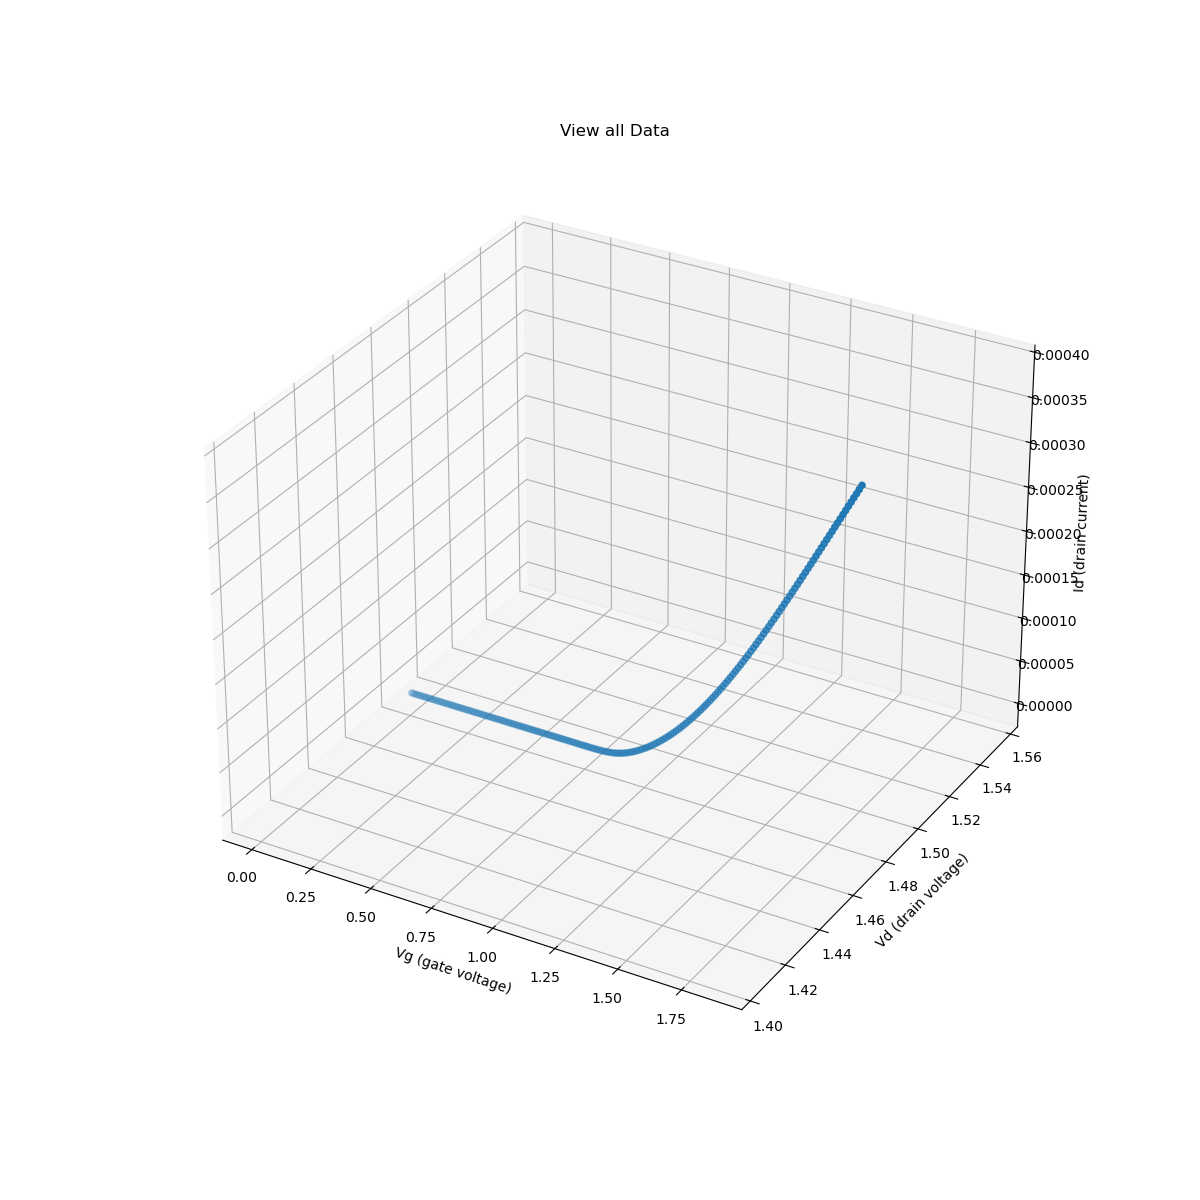

In [36]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')

if 'all' in plot_what_data:
    for i, row in X_iv.iterrows():
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
elif 'one curve' in plot_what_data:
    n = 0
    for i, row in X_iv.iterrows():
        if n>0:
            continue
        print(row)
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
        n+=1
else:
    print('please give a valid value for plot_what_data')
        
_ = ax.set_xlabel('Vg (gate voltage)')
_ = ax.set_ylabel('Vd (drain voltage)')
_ = ax.set_zlabel('Id (drain current)')
_ = ax.set_title('View all Data')
plt.show()

In [37]:
plt.savefig('plots/tenThousandSamples.png')
plt.close()

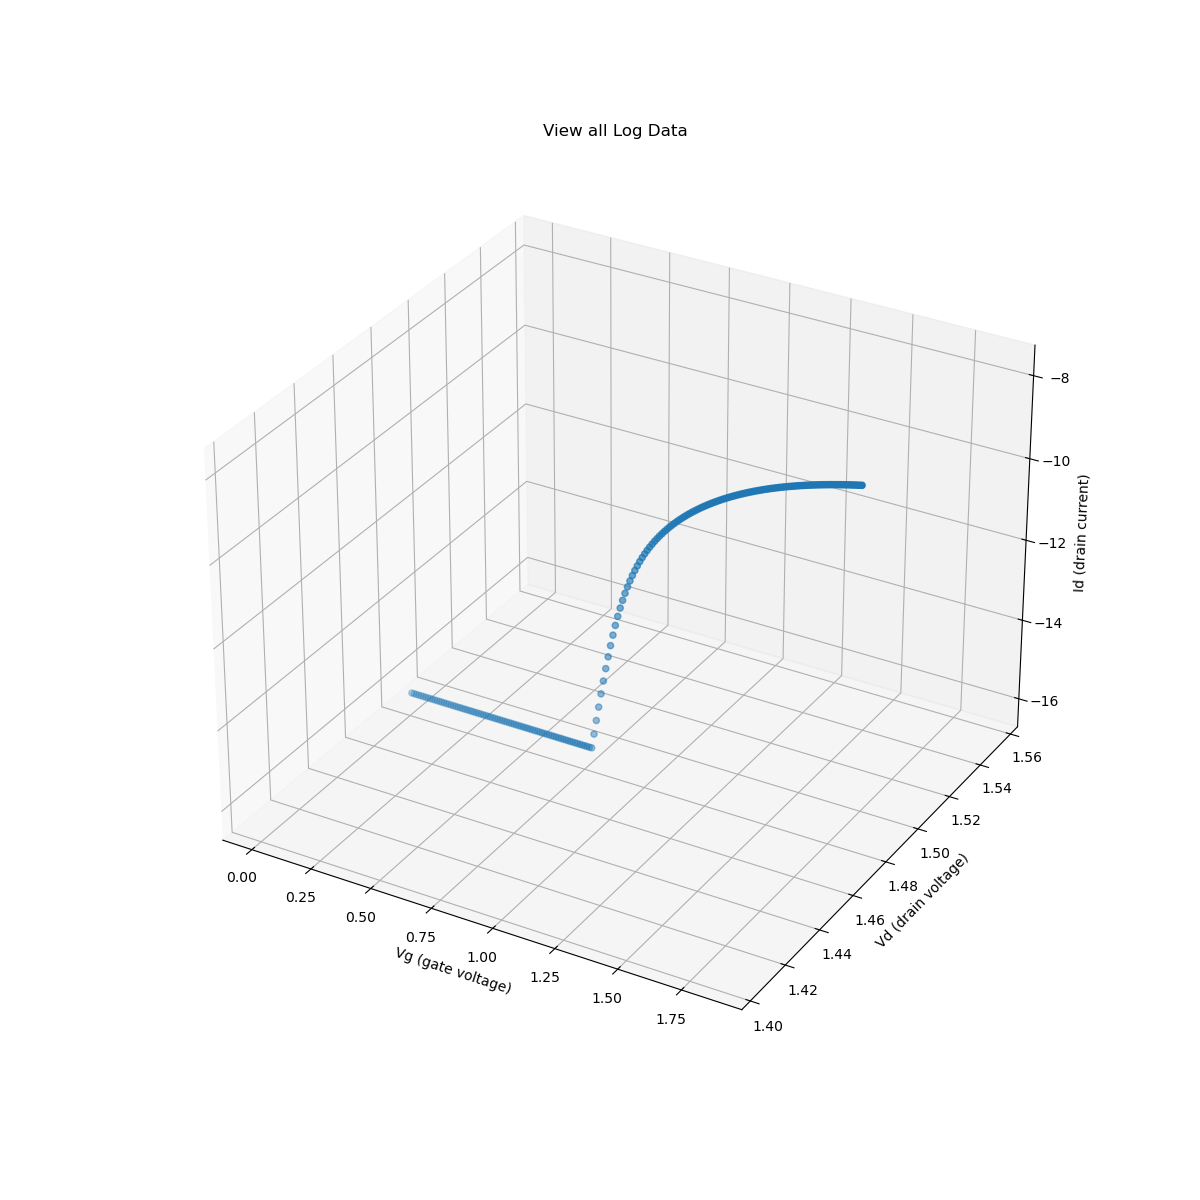

In [40]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')


if 'all' in plot_what_data:
    for i, row in X_iv_log.iterrows():
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
elif 'one curve' in plot_what_data:
    n = 0
    for i, row in X_iv_log.iterrows():
        if n>0:
            continue
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
        n+=1
else:
    print('please give a valid value for plot_what_data')

_ = ax.set_xlabel('Vg (gate voltage)')
_ = ax.set_ylabel('Vd (drain voltage)')
_ = ax.set_zlabel('Id (drain current)')
_ = ax.set_title('View all Log Data')
plt.show()

In [41]:
plt.savefig('plots/tenThousandSamplesLog.png')
plt.close()

### Augment 

### Scale X

Scale Id between 0 and 1

In [42]:
import import_ipynb
import numpy as np
from ml_custom_scaler import Scaler
os.makedirs('scalers', exist_ok=True)

In [43]:
# Grab just the training column
X_drain_current = X_iv[['Id']]
X_drain_current_log = X_iv_log[['Id']]

In [44]:
scaler = Scaler()
# Scale both lin/log datasets
scaled_x, global_min_lin, global_max_lin = scaler.scale(X_drain_current)
scaled_x_log, global_min_log, global_max_log = scaler.scale(X_drain_current_log)

Found global min: 1e-07
Found global max: 0.00532901384
Found global min: -16.11809565095832
Found global max: -5.234589078560712


In [45]:
# Save these scaling factors so you can use them later for input measurement data
file_path = 'scaling_boundaries.txt'

# Write the values to the text file
with open(file_path, 'w') as file:
    file.write(f"min_lin: {global_min_lin}\n")
    file.write(f"max_lin: {global_max_lin}\n")
    file.write(f"min_log: {global_min_log}\n")
    file.write(f"max_log: {global_max_log}\n")

print(f"Variables have been saved to {file_path}")

Variables have been saved to scaling_boundaries.txt


In [46]:
# Check the scaling
display(scaled_x)

,Scaled_Id
0,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
1,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
2,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
3,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
4,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
...,...
5386,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
5387,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
5388,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."
5389,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ..."


NameError: name 'line2_2' is not defined

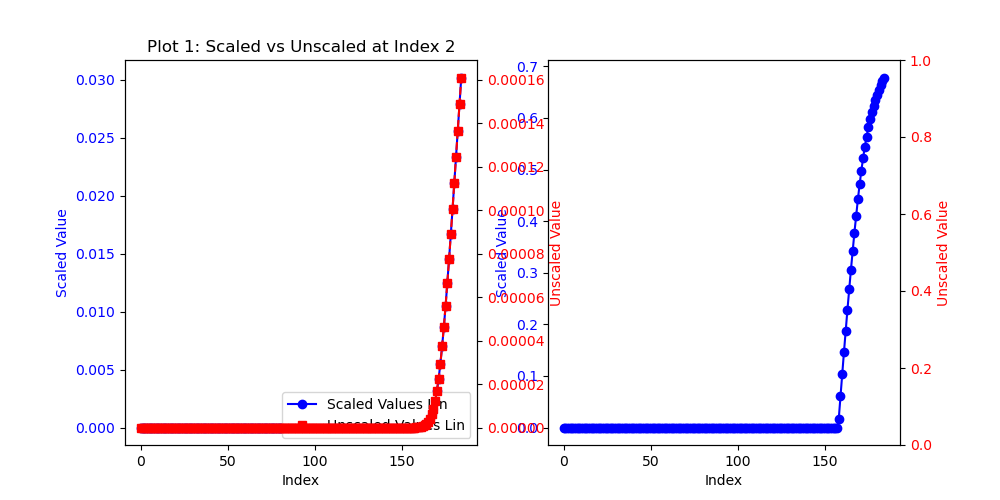

In [48]:
import matplotlib.pyplot as plt

# Plot the scaled vs unscaled list in index 2 (or some other random index) to validate the data ordering is still correct
# Assuming scaled_x and X_drain_current are pre-defined DataFrames
i = 2
sample_scaled_values_1 = scaled_x['Scaled_Id'].iloc[i]
sample_unscaled_values_1 = X_drain_current['Id'].iloc[i]

# Create a new set of sample data for the second plot
sample_scaled_values_2 = scaled_x_log['Scaled_Id'].iloc[i]
sample_unscaled_values_2 = X_drain_current_log['Id'].iloc[i]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5))

# First plot
line1_1, = ax1.plot(sample_scaled_values_1, marker='o', linestyle='-', color='b', label='Scaled Values Lin')
ax1.set_xlabel('Index')
ax1.set_ylabel('Scaled Value', color='b')
ax1.tick_params(axis='y', labelcolor='b')
ax1_twin = ax1.twinx()

line1_2, = ax1_twin.plot(sample_unscaled_values_1, marker='s', linestyle='--', color='r', label='Unscaled Values Lin')
ax1_twin.set_ylabel('Unscaled Value', color='r')
ax1_twin.tick_params(axis='y', labelcolor='r')

lines_1 = [line1_1, line1_2]
ax1.legend(lines_1, [line.get_label() for line in lines_1], loc='lower right')
ax1.set_title('Plot 1: Scaled vs Unscaled at Index '+str(i))

# Second plot
line2_1, = ax2.plot(sample_scaled_values_2, marker='o', linestyle='-', color='b', label='Scaled Values Log')
ax2.set_xlabel('Index')
ax2.set_ylabel('Scaled Value', color='b')
ax2.tick_params(axis='y', labelcolor='b')
ax2_twin = ax2.twinx()

#line2_2, = ax2_twin.plot(sample_unscaled_values_2, marker='s', linestyle='--', color='r', label='Unscaled Values Log')
ax2_twin.set_ylabel('Unscaled Value', color='r')
ax2_twin.tick_params(axis='y', labelcolor='r')

lines_2 = [line2_1, line2_2]
ax2.legend(lines_2, [line.get_label() for line in lines_2], loc='lower right')
ax2.set_title('Plot 2: Scaled vs Unscaled at Index '+str(i))

plt.tight_layout()
plt.suptitle('Comparison of Scaled and Unscaled Values')
plt.subplots_adjust(top=0.85) 
plt.show()

In [49]:
print(np.min(sample_scaled_values_1))
print(np.min(sample_scaled_values_2))

0.0
0.0


In [50]:
# Rename the scaled column to just Id 
print(X_iv["Id"].iloc[0][:10])
scaled_x = scaled_x.rename(columns={'Scaled_Id': 'Id'})
scaled_x_log = scaled_x_log.rename(columns={'Scaled_Id': 'Id'})

# Add back in the 'Vg' and 'Vd' column so we can use them in the next script
scaled_x = pd.concat([X_iv[['Vg', 'Vd']], scaled_x], axis=1)
scaled_x_log = pd.concat([X_iv_log[['Vg', 'Vd']], scaled_x_log], axis=1)
print(scaled_x["Id"].iloc[0][:10])
# Display the resulting DataFrame
print(scaled_x)

[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07]
[np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0), np.float64(0.0)]
                                                     Vg  \
0     [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
1     [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
2     [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
3     [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
4     [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
...                                                 ...   
5386  [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
5387  [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
5388  [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
5389  [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   
5390  [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...   

                                                 

### Scale Y Potentially

Scale each parameter individually and save the scalers in the folder 'scalers'

In [51]:
if SCALE_Y:
    from sklearn.preprocessing import MinMaxScaler
    import joblib
    
    y_iv_scaled = y_iv.copy()
    for col in y_iv_scaled.columns:
        scaler = MinMaxScaler()
        y_iv_scaled[col] = scaler.fit_transform(y_iv_scaled[[col]]) #only fit to this column
        joblib.dump(scaler, f'scalers/scaler_y_{col}.save') #save for later

In [52]:
if SCALE_Y:
    display(y_iv_scaled)

,vth0_nom,vsat_nom,rdsw_nom,u0_nom,nfactor_nom,eta0_nom,delta_nom
0,0.231687,0.721472,0.160109,0.009325,0.846000,0.924849,0.500504
1,0.059910,0.096882,0.757564,0.257679,0.663342,0.052942,0.352717
2,0.687152,0.260978,0.223141,0.640059,0.577930,0.675996,0.550968
3,0.839777,0.177136,0.240895,0.743461,0.401271,0.384696,0.256867
4,0.581840,0.362472,0.221163,0.402701,0.667405,0.547340,0.859639
...,...,...,...,...,...,...,...
5386,0.700252,0.202076,0.829672,0.980851,0.538829,0.448581,0.216505
5387,0.790605,0.955178,0.201435,0.060935,0.431956,0.848135,0.579567
5388,0.560711,0.785530,0.621341,0.999306,0.625383,0.357723,0.995318
5389,0.265533,0.776478,0.853938,0.063996,0.725234,0.749079,0.776187


### Plot Scaled X Data

Takes a long time, skip or section data as needed

Vg    [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...
Vd    [1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...
Id    [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...
Name: 0, dtype: object


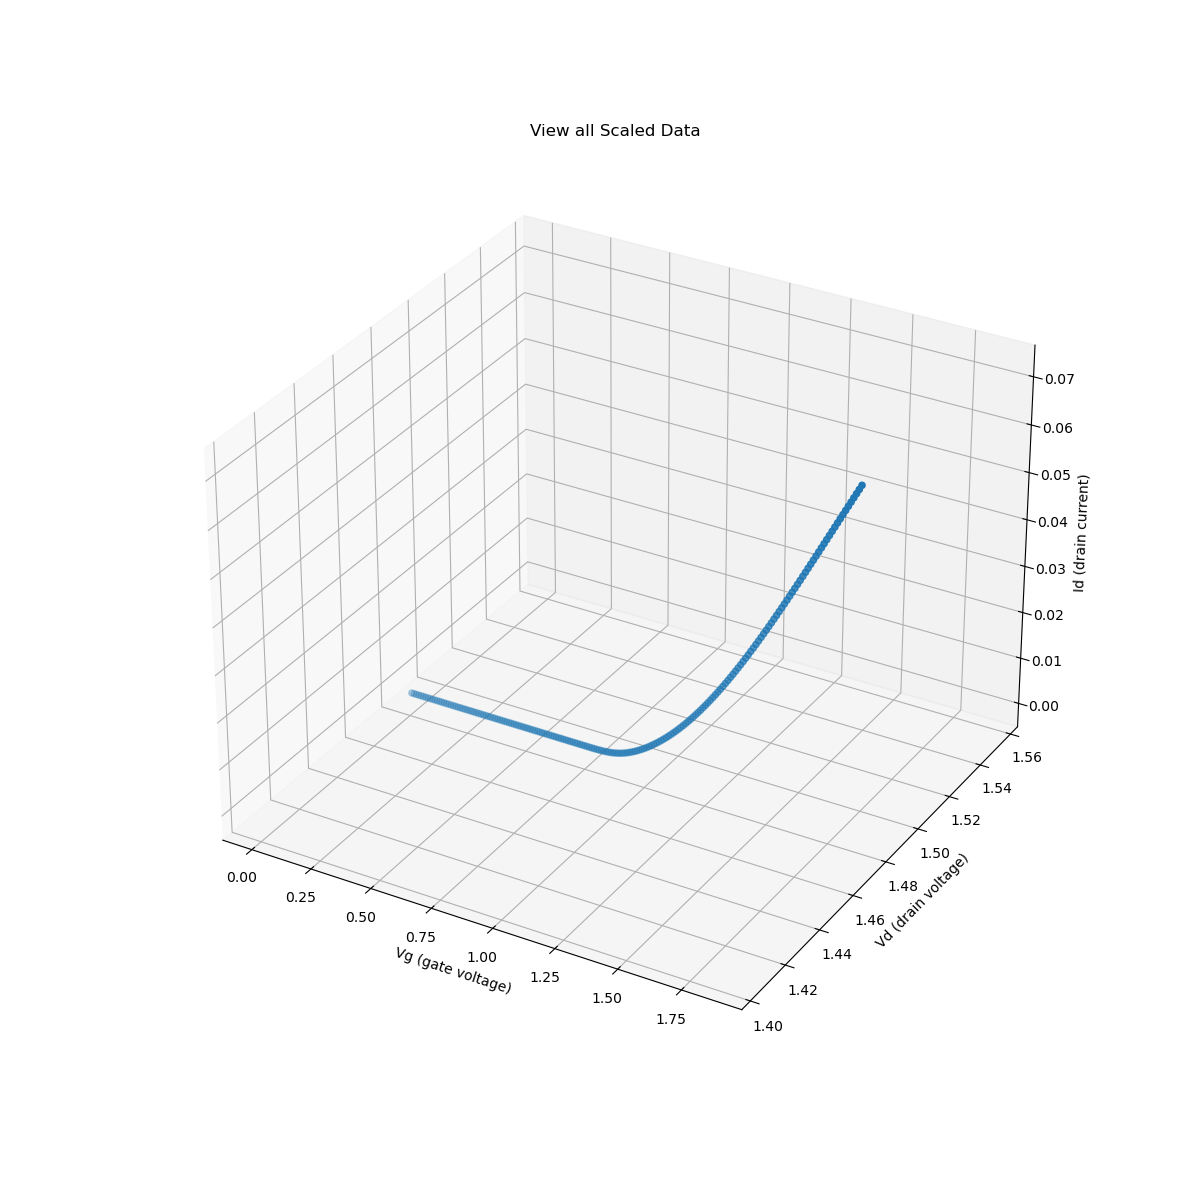

In [53]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')

if 'all' in plot_what_data:
    for i, row in scaled_x.iterrows():
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
elif 'one curve' in plot_what_data:
    n = 0
    for i, row in scaled_x.iterrows():
        if n>0:
            continue
        print(row)
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
        n+=1
else:
    print('please give a valid value for plot_what_data')

_ = ax.set_xlabel('Vg (gate voltage)')
_ = ax.set_ylabel('Vd (drain voltage)')
_ = ax.set_zlabel('Id (drain current)')
_ = ax.set_title('View all Scaled Data')
plt.show()

In [54]:
plt.savefig('plots/tenThousandSamplesScaled.png')
plt.close()

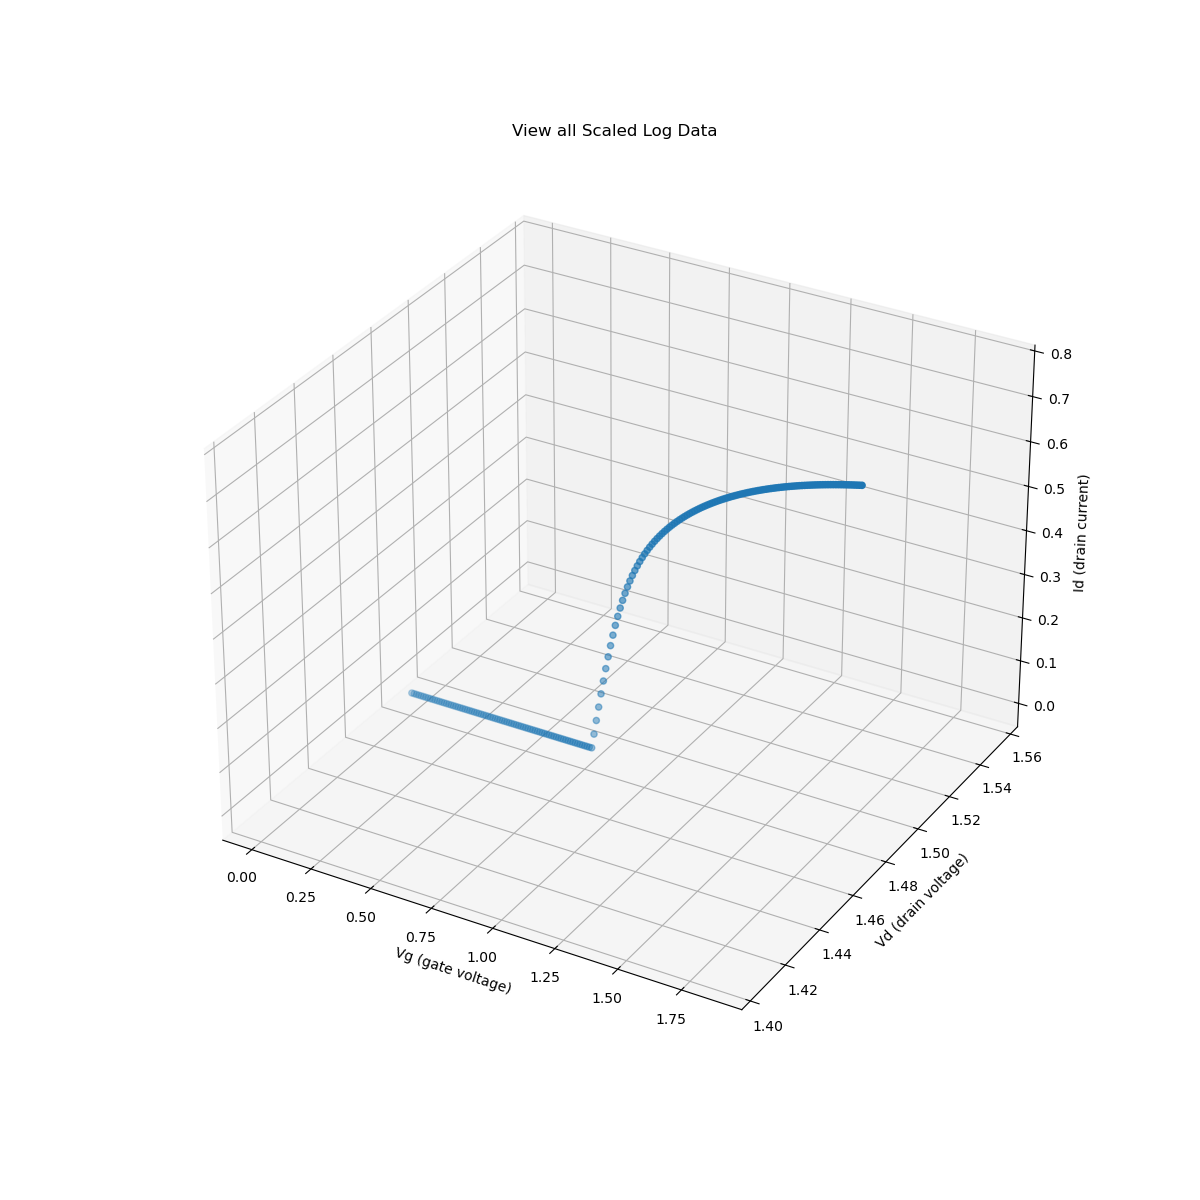

In [55]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')

if 'all' in plot_what_data:
    for i, row in scaled_x_log.iterrows():
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
if 'one curve' in plot_what_data:
    n = 0
    for i, row in scaled_x_log.iterrows():
        if n>0:
            continue
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
        n+=1
else:
    print('please give a valid value for plot_what_data')

_ = ax.set_xlabel('Vg (gate voltage)')
_ = ax.set_ylabel('Vd (drain voltage)')
_ = ax.set_zlabel('Id (drain current)')
_ = ax.set_title('View all Scaled Log Data')
plt.show()

In [56]:
plt.savefig('plots/tenThousandSamplesScaledLog.png')
plt.close()

### Unscale Y to check

In [57]:
if SCALE_Y:
    y_iv_unscaled = y_iv_scaled.copy()
    for col in y_iv_scaled.columns:
        scaler = joblib.load(f'scalers/scaler_y_{col}.save')
        y_iv_unscaled[col] = scaler.inverse_transform(y_iv_unscaled[[col]]) 
    
    display(y_iv_unscaled)

,vth0_nom,vsat_nom,rdsw_nom,u0_nom,nfactor_nom,eta0_nom,delta_nom
0,1.529348,7.241591,1.768795,0.779769,42.304049,9.254957,5.005415
1,0.470126,1.059325,7.622571,3.091075,33.192301,0.624853,3.527795
2,4.337858,2.683569,2.386375,6.649698,28.931555,6.791817,5.509971
3,5.278981,1.853695,2.560327,7.612009,20.119030,3.908542,2.569450
4,3.688473,3.688173,2.366994,4.440724,33.394975,5.518391,8.596162
...,...,...,...,...,...,...,...
5386,4.418632,2.100554,8.329074,9.821273,26.981034,4.540875,2.165905
5387,4.975770,9.554841,2.173697,1.260074,21.649764,8.495643,5.795909
5388,3.558188,7.875646,6.287878,9.993032,31.298740,3.641570,9.952720
5389,1.738051,7.786049,8.566830,1.288562,36.279732,7.515193,7.761780


### Split

In [58]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.model_selection import train_test_split

Dataset split is 80%-20% training-validation and test sets. We use a constant state (seed) for reproducible splits across multiple runs.

In [59]:
# This should split the same way for linear and log scale because eof the random_state variable
if SCALE_Y:
    X_iv_train_val, X_iv_test, y_iv_train_val, y_iv_test = train_test_split(X_iv, y_iv, test_size=0.2, random_state=42, shuffle=True)
    X_iv_train_val_augmented, X_iv_test_augmented, y_iv_train_val_augmented, y_iv_test_augmented = train_test_split(scaled_x, y_iv_scaled, test_size=0.2, random_state=42, shuffle=True)
    
    X_iv_train_val_log, X_iv_test_log, y_iv_train_val, y_iv_test = train_test_split(X_iv_log, y_iv, test_size=0.2, random_state=42, shuffle=True)
    X_iv_train_val_augmented_log, X_iv_test_augmented_log, y_iv_train_val_augmented, y_iv_test_augmented = train_test_split(scaled_x_log, y_iv_scaled, test_size=0.2, random_state=42, shuffle=True)

else:
    X_iv_train_val, X_iv_test, y_iv_train_val, y_iv_test = train_test_split(X_iv, y_iv, test_size=0.2, random_state=42, shuffle=True)
    X_iv_train_val_augmented, X_iv_test_augmented, y_iv_train_val_augmented, y_iv_test_augmented = train_test_split(scaled_x, y_iv, test_size=0.2, random_state=42, shuffle=True)
    
    X_iv_train_val_log, X_iv_test_log, y_iv_train_val, y_iv_test = train_test_split(X_iv_log, y_iv, test_size=0.2, random_state=42, shuffle=True)
    X_iv_train_val_augmented_log, X_iv_test_augmented_log, y_iv_train_val_augmented, y_iv_test_augmented = train_test_split(scaled_x_log, y_iv, test_size=0.2, random_state=42, shuffle=True)
#print(X_iv_train_val.iloc[300][2])
#print(len(X_iv_test.iloc[1][2]))


In [60]:
indices = np.arange(len(X_iv))
train_idx, test_idx = train_test_split(indices, test_size=0.2, random_state=42, shuffle=True)

# 2. Slice all DataFrame features and targets using .iloc
if SCALE_Y:
    X_iv_train_val, X_iv_test                   = X_iv.iloc[train_idx], X_iv.iloc[test_idx]
    X_iv_train_val_augmented, X_iv_test_augmented = scaled_x.iloc[train_idx], scaled_x.iloc[test_idx]
    
    X_iv_train_val_log, X_iv_test_log           = X_iv_log.iloc[train_idx], X_iv_log.iloc[test_idx]
    X_iv_train_val_augmented_log, X_iv_test_augmented_log = scaled_x_log.iloc[train_idx], scaled_x_log.iloc[test_idx]
    
    y_iv_train_val, y_iv_test                   = y_iv.iloc[train_idx], y_iv.iloc[test_idx]
    y_iv_train_val_augmented, y_iv_test_augmented = y_iv_scaled.iloc[train_idx], y_iv_scaled.iloc[test_idx]

else:
    X_iv_train_val, X_iv_test                   = X_iv.iloc[train_idx], X_iv.iloc[test_idx]
    X_iv_train_val_augmented, X_iv_test_augmented = scaled_x.iloc[train_idx], scaled_x.iloc[test_idx]
    
    X_iv_train_val_log, X_iv_test_log           = X_iv_log.iloc[train_idx], X_iv_log.iloc[test_idx]
    X_iv_train_val_augmented_log, X_iv_test_augmented_log = scaled_x_log.iloc[train_idx], scaled_x_log.iloc[test_idx]
    
    y_iv_train_val, y_iv_test                   = y_iv.iloc[train_idx], y_iv.iloc[test_idx]
    y_iv_train_val_augmented, y_iv_test_augmented = y_iv.iloc[train_idx], y_iv.iloc[test_idx]

In [61]:
total = y_iv_train_val.shape[0] + y_iv_test.shape[0]
print('---------------------------------------')
print('Train-and-validation set shape: {}, {:.2f}%'.format(y_iv_train_val.shape, (y_iv_train_val.shape[0]*100.)/total))
print('Test set shape:                 {}, {:.2f}%'.format(y_iv_test.shape, (y_iv_test.shape[0]*100.)/total))
print('---------------------------------------')

---------------------------------------
Train-and-validation set shape: (4312, 7), 79.99%
Test set shape:                 (1079, 7), 20.01%
---------------------------------------


In [62]:
total = y_iv_train_val_augmented.shape[0] + y_iv_test_augmented.shape[0]
print('---------------------------------------')
print('Train-and-validation set shape: {}, {:.2f}%'.format(y_iv_train_val_augmented.shape, (y_iv_train_val_augmented.shape[0]*100.)/total))
print('Test set shape:                 {}, {:.2f}%'.format(y_iv_test_augmented.shape, (y_iv_test_augmented.shape[0]*100.)/total))
print('---------------------------------------')
print(X_iv_train_val.iloc[2])
#print(X_iv_test.iloc[2][2])

---------------------------------------
Train-and-validation set shape: (4312, 7), 79.99%
Test set shape:                 (1079, 7), 20.01%
---------------------------------------
Vg    [0.01, 0.02, 0.03, 0.04, 0.05, 0.06, 0.07, 0.0...
Vd    [1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.48, 1.4...
Id    [1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-...
Name: 621, dtype: object


### Save

Save the split data set for future reference

In [63]:
!rm -f $DATA_DIR/npy/*npy
os.makedirs(f'{DATA_DIR}', exist_ok=True)
os.makedirs(f'{DATA_DIR}/npy', exist_ok=True)

In [64]:
np.save('{}/npy/x_iv_train_val.npy'.format(DATA_DIR), X_iv_train_val)
np.save('{}/npy/x_iv_test.npy'.format(DATA_DIR), X_iv_test)
np.save('{}/npy/x_iv_train_val_log.npy'.format(DATA_DIR), X_iv_train_val_log)
np.save('{}/npy/x_iv_test_log.npy'.format(DATA_DIR), X_iv_test_log)
np.save('{}/npy/y_iv_train_val.npy'.format(DATA_DIR), y_iv_train_val)
np.save('{}/npy/y_iv_test.npy'.format(DATA_DIR), y_iv_test)

print('Data saved in: {}/npy'.format(DATA_DIR))

Data saved in: training_data/nmos_FET_len_0p15_wid_1p6/npy


In [65]:
np.save('{}/npy/x_iv_train_val_augmented.npy'.format(DATA_DIR), X_iv_train_val_augmented)
np.save('{}/npy/x_iv_test_augmented.npy'.format(DATA_DIR), X_iv_test_augmented)
np.save('{}/npy/x_iv_train_val_augmented_log.npy'.format(DATA_DIR), X_iv_train_val_augmented_log)
np.save('{}/npy/x_iv_test_augmented_log.npy'.format(DATA_DIR), X_iv_test_augmented_log)
np.save('{}/npy/y_iv_train_val_augmented.npy'.format(DATA_DIR), y_iv_train_val_augmented)
np.save('{}/npy/y_iv_test_augmented.npy'.format(DATA_DIR), y_iv_test_augmented)

print('Data saved in: {}/npy'.format(DATA_DIR))

Data saved in: training_data/nmos_FET_len_0p15_wid_1p6/npy


In [66]:
!ls $DATA_DIR/npy/*npy

training_data/nmos_FET_len_0p15_wid_1p6/npy/x_iv_test_augmented_log.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/x_iv_test_augmented.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/x_iv_test_log.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/x_iv_test.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/x_iv_train_val_augmented_log.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/x_iv_train_val_augmented.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/x_iv_train_val_log.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/x_iv_train_val.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/y_iv_test_augmented.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/y_iv_test.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/y_iv_train_val_augmented.npy
training_data/nmos_FET_len_0p15_wid_1p6/npy/y_iv_train_val.npy


### Visualize

Modify to visualize scaled or unscaled values as needed. Takes a long time so you can also sample data for efficiency

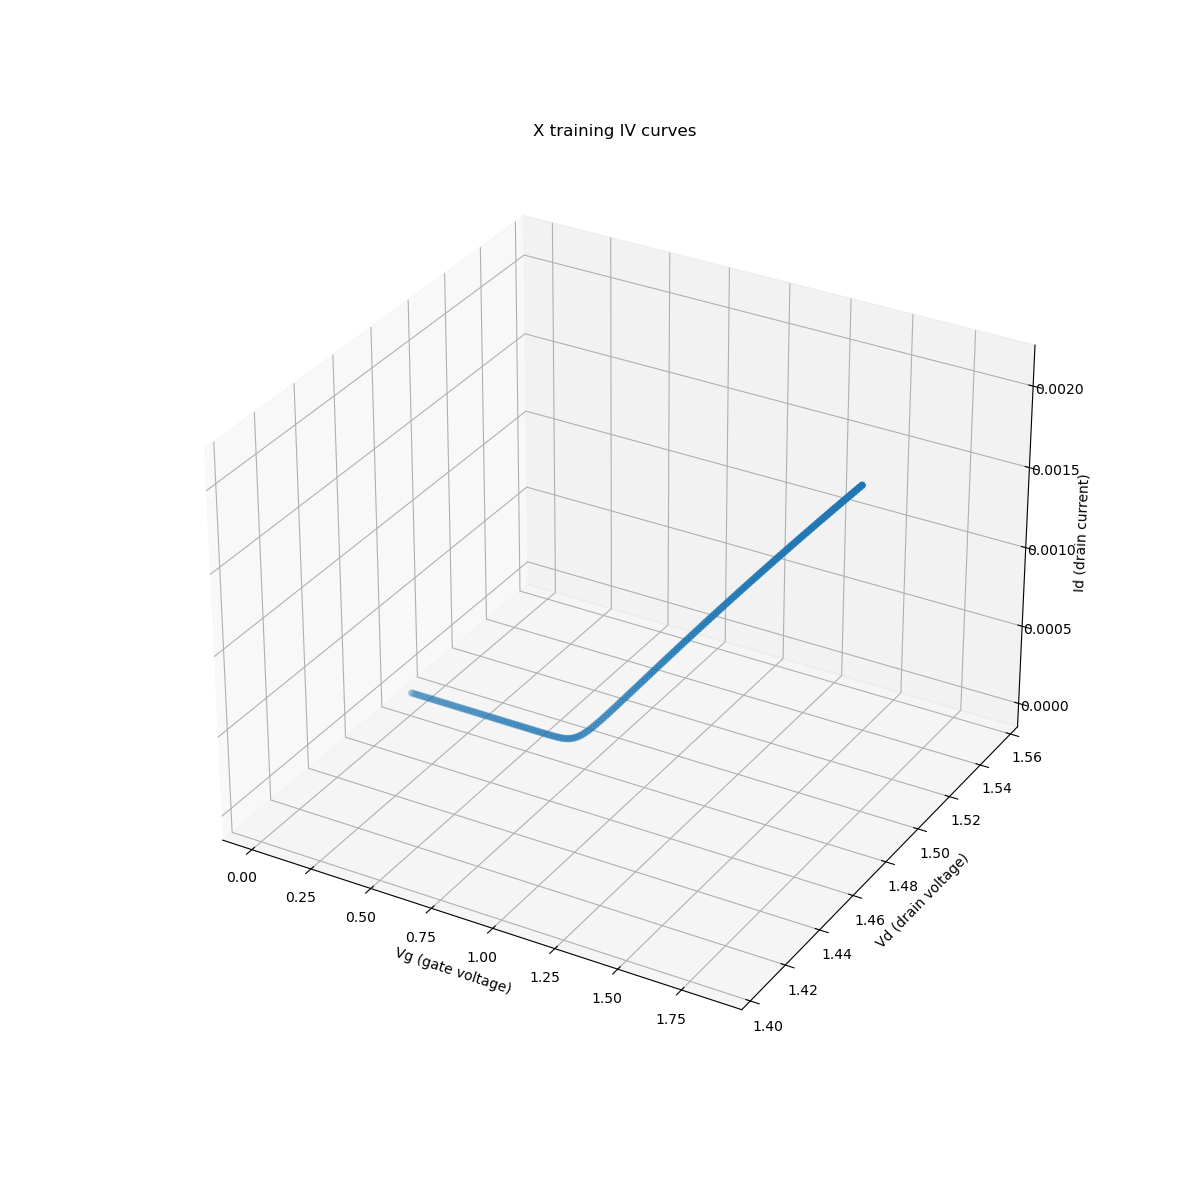

In [67]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')


if 'all' in plot_what_data:
    for i, row in X_iv_train_val.iterrows():
        Vg, Vd, Id = row
       
        ax.scatter(Vg, Vd, Id)
elif 'one curve' in plot_what_data:
    n = 0
    for i, row in X_iv_train_val.iterrows():
        if n>0:
            continue
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
        n+=1
else:
    print('please give a valid value for plot_what_data')

_ = ax.set_xlabel('Vg (gate voltage)')
_ = ax.set_ylabel('Vd (drain voltage)')
_ = ax.set_zlabel('Id (drain current)')
_ = ax.set_title('X training IV curves')
plt.show()

In [68]:
#plt.savefig('plots/xTrainingDataUnscaled.png')
plt.close()
print(plot_what_data)
print(Id)
#print(X_iv_train_val)

one curve
[1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1e-07, 1.05943608e-07, 1.74906456e-07, 2.86232606e-07, 4.63692844e-07, 7.42674695e-07, 1.17478009e-06, 1.83361432e-06, 2.82144443e-06, 4.27539571e-06, 6.37023233e-06, 9.31337837e-06, 1.33284474e-05, 1.86274892e-05, 2.53782093e-05, 3.36766082e-05, 4.35342571e-05, 5.48832309e-05, 6.75947245e-05, 8.15036588e-05, 9.64320671e-05, 0.00011220697, 0.000128671546, 0.000145690443, 0.000163150885, 0.000180961236, 0.000199048322, 0.000217354362, 0.000235834016, 0.000254451773, 0.000273179775, 0.000291996067, 0.000310883219, 0.000329827261, 0.000348816879, 0.000367842801, 0.000386897336, 0.000405974032, 0.0004

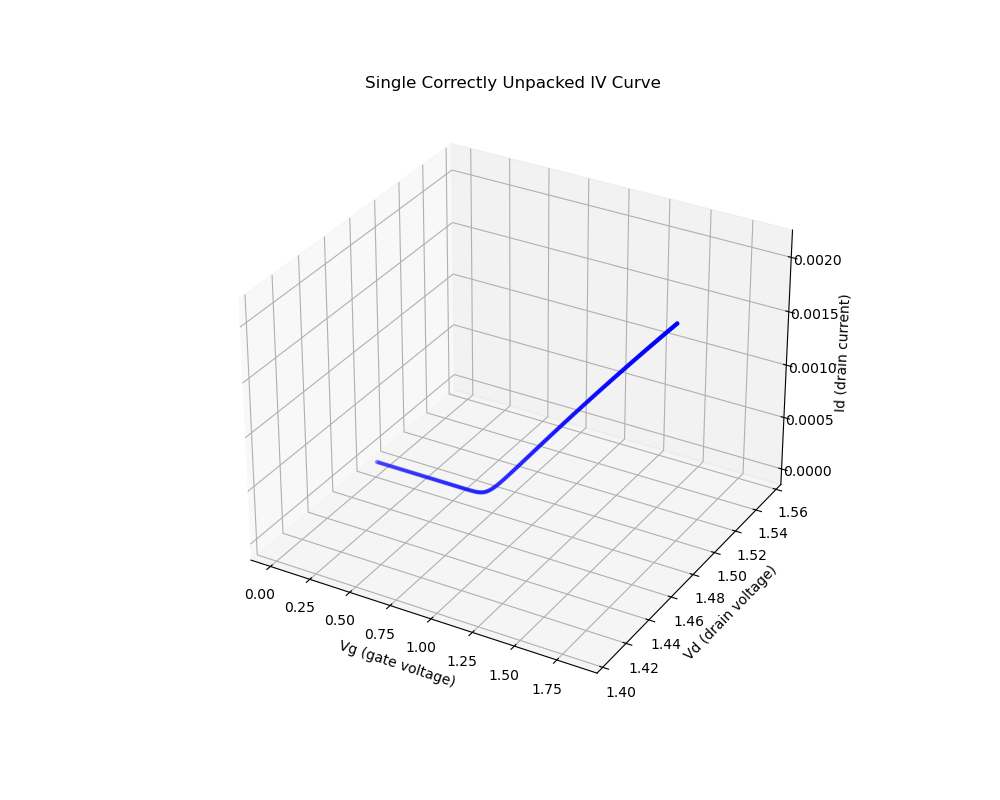

In [69]:
import ast
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(projection='3d')

# 1. Grab just one row safely using column names
row = X_iv_train_val.iloc[0]

# 2. Convert stringified lists to actual numerical lists/arrays
# (Replace 'Vg', 'Vd', 'Id' with your exact DataFrame column names if they differ)
Vg = row['Vg']
Vd = row['Vd']
Id = row['Id']

# 3. Plot the single curve
ax.scatter(Vg, Vd, Id, color='blue', s=5)

ax.set_xlabel('Vg (gate voltage)')
ax.set_ylabel('Vd (drain voltage)')
ax.set_zlabel('Id (drain current)')
ax.set_title('Single Correctly Unpacked IV Curve')

plt.show()

In [70]:
plt.close()

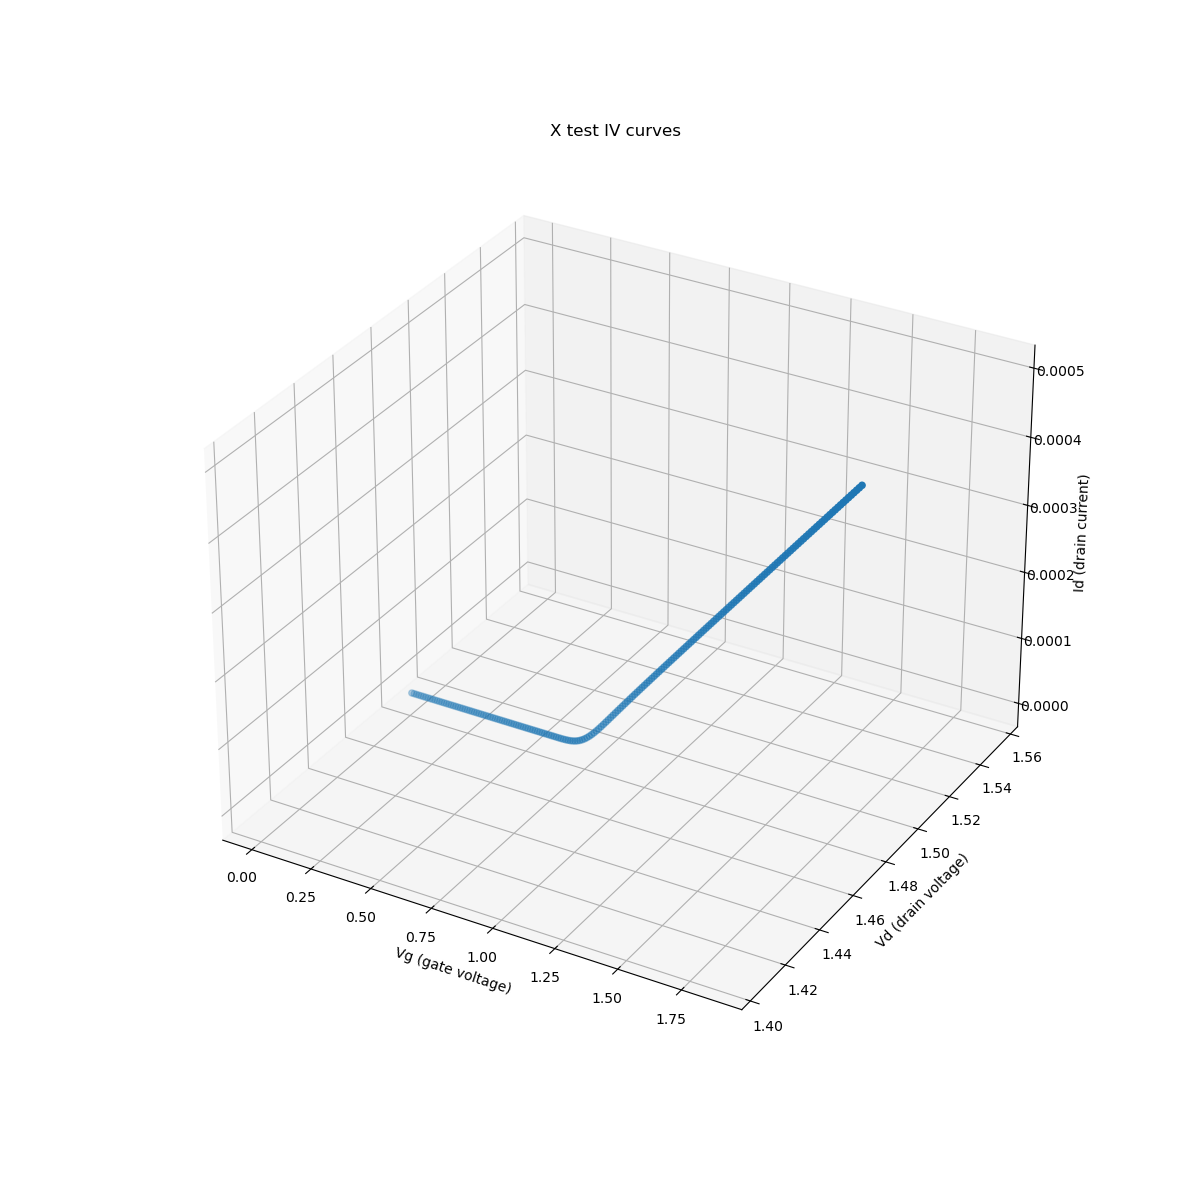

In [71]:
fig = plt.figure(figsize=(12, 12))
ax = fig.add_subplot(projection='3d')

if 'all' in plot_what_data:
    for i, row in X_iv_test.iterrows():
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
elif 'one curve' in plot_what_data:
    n = 0
    for i, row in X_iv_test.iterrows():
        if n>0:
            continue
        Vg, Vd, Id = row
        ax.scatter(Vg, Vd, Id)
        n+=1
else:
    print('please give a valid value for plot_what_data')

_ = ax.set_xlabel('Vg (gate voltage)')
_ = ax.set_ylabel('Vd (drain voltage)')
_ = ax.set_zlabel('Id (drain current)')
_ = ax.set_title('X test IV curves')
plt.show()

In [72]:
plt.savefig('plots/xTestDataUnscaled.png')
plt.close()